# B1 — DDR

Conservative training augmentation may improve generalization while preserving retinal field of view.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

Exact recorded main training module matched by SHA-256 to [the archived source](https://github.com/salmakamila126/Diabetic-Rethinography/blob/3a563c67fef82454ce2ed34858615bd456424a13/novelty/foundation_adaptation.py). The optional CLI uses the current [foundation adaptation](../../novelty/foundation_adaptation.py) for a separately recorded new run.

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A linear categorical head emits five logits. Parameter counts are not published in this run evidence.

EXIF transpose and RGB, then the pinned official processor at 224 px for resize/crop, rescale and normalization. B1 train-only augmentation is keyed by seed, epoch and image ID. It applies horizontal flip (p=0.50), field-of-view guarded rotation (p=0.50, ±7°), brightness (p=0.30, factor 0.90–1.10), and contrast (p=0.30, factor 0.90–1.10), in that order.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'B1', 'DDR'
EVIDENCE = 'novelty/convnext_b0_b4/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [r for r in blob['runs'] if r['dataset'] == DATASET and (r['arm'].startswith('B4-') if METHOD == 'B4' else r['arm'] == METHOD)]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CHECKPOINT_SHA256 = '7ae7b1a64fa1a4c6cc0fa6aa838238ee2b460871bd9dbf9a01dc357bd1d28fe6'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## B1 recorded configuration and history

[Authoritative aggregate JSON](../../novelty/convnext_b0_b4/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| model_kind | convnext_tiny |
| mode | full |
| seed | 42 |
| epochs | 20 |
| micro_batch | 32 |
| accumulation | 1 |
| effective_batch | 32 |
| precision | bf16 |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| selection | max validation macro-F1; tie lower validation loss; tie earliest epoch |
| training_loss | ordinary CE |
| implementation_sha256 | 2b011e422c40f52a03a3d0aa89e0d18285875da1946058c265cc07747a61f300 |
| manifest_sha256 | 7bc3e3916e012bc46fcd9cd69aa469e0daf3229e1273f1d8ecb6054899bf6eb1 |
| train / validation counts | {'train': 10018, 'val': 1252} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "augmentation": {
    "implementation_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "pillow_version": "11.1.0",
    "protocol": {
      "brightness_factor": [
        0.9,
        1.1
      ],
      "brightness_probability": 0.3,
      "contrast_factor": [
        0.9,
        1.1
      ],
      "contrast_probability": 0.3,
      "fov_proxy_threshold_max_channel": 8,
      "horizontal_flip_probability": 0.5,
      "minimum_fov_proxy_retention": 0.99,
      "name": "B1-retinal-conservative-v1",
      "order": [
        "horizontal_flip",
        "rotation",
        "brightness",
        "contrast"
      ],
      "rotation_attempts": 8,
      "rotation_degrees": [
        -7.0,
        7.0
      ],
      "rotation_fill": [
        0,
        0,
        0
      ],
      "rotation_probability": 0.5,
      "rotation_resample": "BICUBIC"
    }
  }
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.751016 | 0.717508 | 0.396589 | 0.685486 | 0.650783 | 0.513975 |
| 2 | 0.575354 | 0.790777 | 0.490794 | 0.763464 | 0.784818 | 0.354662 |
| 3 | 0.510501 | 0.81643 | 0.551366 | 0.792067 | 0.821613 | 0.303154 |
| 4 | 0.460078 | 0.832701 | 0.589549 | 0.81067 | 0.841478 | 0.272609 |
| 5 | 0.411148 | 0.849271 | 0.619645 | 0.829667 | 0.864953 | 0.23887 |
| 6 | 0.369819 | 0.867239 | 0.658282 | 0.85076 | 0.887949 | 0.203733 |
| 7 | 0.335963 | 0.881014 | 0.690176 | 0.868009 | 0.905474 | 0.177181 |
| 8 | 0.301896 | 0.891695 | 0.719671 | 0.880822 | 0.917759 | 0.157317 |
| 9 | 0.256763 | 0.908565 | 0.764389 | 0.900917 | 0.932601 | 0.130365 |
| 10 | 0.231308 | 0.915652 | 0.784898 | 0.910057 | 0.940101 | 0.118087 |
| 11 | 0.195758 | 0.932521 | 0.834803 | 0.928752 | 0.952469 | 0.0945298 |
| 12 | 0.168988 | 0.939709 | 0.850619 | 0.937176 | 0.959705 | 0.0820523 |
| 13 | 0.144013 | 0.949092 | 0.881572 | 0.947105 | 0.964462 | 0.0703733 |
| 14 | 0.116878 | 0.960671 | 0.90642 | 0.959718 | 0.974578 | 0.052805 |
| 15 | 0.0982027 | 0.967359 | 0.922416 | 0.966728 | 0.979049 | 0.043322 |
| 16 | 0.0810206 | 0.973747 | 0.94147 | 0.973354 | 0.981832 | 0.0364344 |
| 17 | 0.0637707 | 0.979138 | 0.955079 | 0.978814 | 0.986931 | 0.0276502 |
| 18 | 0.0531998 | 0.98313 | 0.963789 | 0.982964 | 0.989073 | 0.0226592 |
| 19 | 0.0373084 | 0.988321 | 0.976856 | 0.988231 | 0.991733 | 0.0164704 |
| 20 | 0.036687 | 0.987722 | 0.979191 | 0.987691 | 0.990404 | 0.0182671 |

### Validation metrics

| Epoch | CE | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.641819 | 0.764377 | 0.451194 | 0.734057 | 0.738515 | 0.408946 |
| 2 | 0.591314 | 0.783546 | 0.522654 | 0.756883 | 0.772517 | 0.373003 |
| 3 | 0.561557 | 0.795527 | 0.5641 | 0.772859 | 0.791262 | 0.350639 |
| 4 | 0.55141 | 0.801917 | 0.571444 | 0.77818 | 0.807103 | 0.335463 |
| 5 | 0.569026 | 0.798722 | 0.602246 | 0.784332 | 0.803694 | 0.336262 |
| 6 | 0.580248 | 0.801118 | 0.598703 | 0.78911 | 0.808067 | 0.327476 |
| 7 | 0.545187 | 0.827476 | 0.588993 | 0.805781 | 0.83545 | 0.281949 |
| 8 | 0.541178 | 0.82508 | 0.621227 | 0.809469 | 0.834713 | 0.284345 |
| 9 | 0.557542 | 0.825879 | 0.629988 | 0.810373 | 0.835598 | 0.282748 |
| 10 | 0.608284 | 0.829073 | 0.611322 | 0.80749 | 0.834818 | 0.28115 |
| 11 | 0.590888 | 0.826677 | 0.652146 | 0.818245 | 0.843538 | 0.275559 |
| 12 | 0.652838 | 0.821885 | 0.647453 | 0.813171 | 0.831064 | 0.288339 |
| 13 | 0.686759 | 0.829073 | 0.639528 | 0.817042 | 0.846997 | 0.269169 |
| 14 | 0.713129 | 0.817891 | 0.650608 | 0.813741 | 0.844735 | 0.278754 |
| 15 | 0.776385 | 0.822684 | 0.642364 | 0.814287 | 0.835657 | 0.281949 |
| 16 | 0.803973 | 0.808307 | 0.636078 | 0.807252 | 0.841219 | 0.289137 |
| 17 | 0.854332 | 0.823482 | 0.641106 | 0.817137 | 0.853336 | 0.269169 |
| 18 | 0.890317 | 0.827476 | 0.650785 | 0.820208 | 0.858025 | 0.263578 |
| 19 | 1.01762 | 0.81869 | 0.643147 | 0.810228 | 0.839879 | 0.286741 |
| 20 | 1.07615 | 0.814696 | 0.643931 | 0.808792 | 0.834806 | 0.29393 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 2455.16 | 2.75324 | 2413.9 | 1.1423 | 4.08039 | 454.738 | 2686451712 | 3417079808 | 200 | 95 | 23 |
| 2 | 2462.93 | 2.91065 | 2421.84 | 1.30269 | 4.06752 | 430.144 | 2688548864 | 3579613184 | 184 | 87 | 32 |
| 3 | 2409.55 | 2.75636 | 2368.44 | 1.1476 | 4.15762 | 454.222 | 2688548864 | 3579613184 | 138 | 118 | 26 |
| 4 | 2511.29 | 2.76264 | 2464.88 | 1.15969 | 3.98918 | 453.19 | 2688548864 | 3579613184 | 149 | 99 | 47 |
| 5 | 2488.4 | 2.76785 | 2447.27 | 1.16065 | 4.02588 | 452.337 | 2688548864 | 3579613184 | 102 | 150 | 40 |
| 6 | 2384.34 | 2.69648 | 2332.3 | 1.10226 | 4.20159 | 464.308 | 2688548864 | 3579613184 | 101 | 148 | 46 |
| 7 | 2424.31 | 2.68265 | 2383.5 | 1.08857 | 4.13231 | 466.702 | 2688548864 | 3579613184 | 128 | 88 | 68 |
| 8 | 2350.56 | 2.68439 | 2309.79 | 1.09007 | 4.26196 | 466.399 | 2688548864 | 3579613184 | 109 | 110 | 56 |
| 9 | 2361.57 | 2.6817 | 2320.8 | 1.08742 | 4.24209 | 466.868 | 2688548864 | 3579613184 | 125 | 93 | 76 |
| 10 | 2434.84 | 2.7795 | 2393.98 | 1.16582 | 4.11444 | 450.441 | 2688548864 | 3579613184 | 119 | 95 | 92 |
| 11 | 2501.35 | 2.76159 | 2460.33 | 1.15426 | 4.00503 | 453.362 | 2688548864 | 3579613184 | 118 | 99 | 76 |
| 12 | 2459.49 | 2.77891 | 2418.44 | 1.16583 | 4.0732 | 450.537 | 2688548864 | 3579613184 | 105 | 118 | 85 |
| 13 | 2469.75 | 2.73594 | 2428.73 | 1.12704 | 4.05629 | 457.613 | 2688548864 | 3579613184 | 132 | 82 | 94 |
| 14 | 2342.02 | 2.6686 | 2301.22 | 1.06866 | 4.2775 | 469.161 | 2688548864 | 3579613184 | 135 | 93 | 95 |
| 15 | 2333.86 | 2.68402 | 2293.12 | 1.08896 | 4.29245 | 466.465 | 2688548864 | 3579613184 | 112 | 110 | 119 |
| 16 | 2587 | 3.12247 | 2539.74 | 1.38532 | 3.87244 | 400.965 | 2734686208 | 4258467840 | 124 | 116 | 108 |
| 17 | 2615.61 | 3.88926 | 2543.34 | 1.132 | 3.83008 | 321.913 | 2734686208 | 4258467840 | 120 | 101 | 116 |
| 18 | 2556.53 | 4.2524 | 2449.78 | 1.15077 | 3.9186 | 294.422 | 2734686208 | 4258467840 | 112 | 104 | 119 |
| 19 | 2603.43 | 4.07233 | 2499.26 | 1.1761 | 3.848 | 307.441 | 2734686208 | 4258467840 | 106 | 121 | 145 |
| 20 | 2592.97 | 4.23062 | 2486.76 | 1.15328 | 3.86352 | 295.938 | 2734686208 | 4258467840 | 103 | 129 | 148 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | — | 1 | True |
| 2 | 1e-05 | 0.001 | — | 2 | True |
| 3 | 1e-05 | 0.001 | — | 3 | True |
| 4 | 1e-05 | 0.001 | — | 4 | True |
| 5 | 1e-05 | 0.001 | — | 5 | True |
| 6 | 1e-05 | 0.001 | — | 5 | False |
| 7 | 1e-05 | 0.001 | — | 5 | False |
| 8 | 1e-05 | 0.001 | — | 8 | True |
| 9 | 1e-05 | 0.001 | — | 9 | True |
| 10 | 1e-05 | 0.001 | — | 9 | False |
| 11 | 1e-05 | 0.001 | — | 11 | True |
| 12 | 1e-05 | 0.001 | — | 11 | False |
| 13 | 1e-05 | 0.001 | — | 11 | False |
| 14 | 1e-05 | 0.001 | — | 11 | False |
| 15 | 1e-05 | 0.001 | — | 11 | False |
| 16 | 1e-05 | 0.001 | — | 11 | False |
| 17 | 1e-05 | 0.001 | — | 11 | False |
| 18 | 1e-05 | 0.001 | — | 11 | False |
| 19 | 1e-05 | 0.001 | — | 11 | False |
| 20 | 1e-05 | 0.001 | — | 11 | False |

## B1 best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 11 | 0.826677 | 0.652146 | 0.818245 | 0.843538 | 0.275559 | 1035 | 217 | 118 | 99 |

Frozen validation only. The selected checkpoint SHA-256 is `7ae7b1a64fa1a4c6cc0fa6aa838238ee2b460871bd9dbf9a01dc357bd1d28fe6`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 574 | 11 | 40 | 0 | 1 |
| 1 | 20 | 11 | 31 | 0 | 1 |
| 2 | 51 | 13 | 371 | 2 | 11 |
| 3 | 0 | 0 | 12 | 10 | 2 |
| 4 | 0 | 0 | 21 | 1 | 69 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 91.6933 | 1.75719 | 6.38978 | 0 | 0.159744 |
| 1 | 31.746 | 17.4603 | 49.2063 | 0 | 1.5873 |
| 2 | 11.3839 | 2.90179 | 82.8125 | 0.446429 | 2.45536 |
| 3 | 0 | 0 | 50 | 41.6667 | 8.33333 |
| 4 | 0 | 0 | 23.0769 | 1.0989 | 75.8242 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.889922 | 0.916933 | 0.903226 | 626 | 574 |
| 1 | 0.314286 | 0.174603 | 0.22449 | 63 | 11 |
| 2 | 0.781053 | 0.828125 | 0.8039 | 448 | 371 |
| 3 | 0.769231 | 0.416667 | 0.540541 | 24 | 10 |
| 4 | 0.821429 | 0.758242 | 0.788571 | 91 | 69 |

Minority-grade predictions on the diagonal were grade 1 11/63, grade 3 10/24. The largest off-diagonal counts were 2 → 0 (51), 0 → 2 (40), 1 → 2 (31). The matrix gives 92 adjacent errors and 125 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Recorded figures

[Learning curves, SVG](../../novelty/convnext_b0_b4/DDR_B1_learning_curves.svg) · [Original PNG](../../novelty/convnext_b0_b4/DDR_B1_confusion_matrix.png). The saved cell output is the original PNG. Rows are true grades and columns are predicted grades.

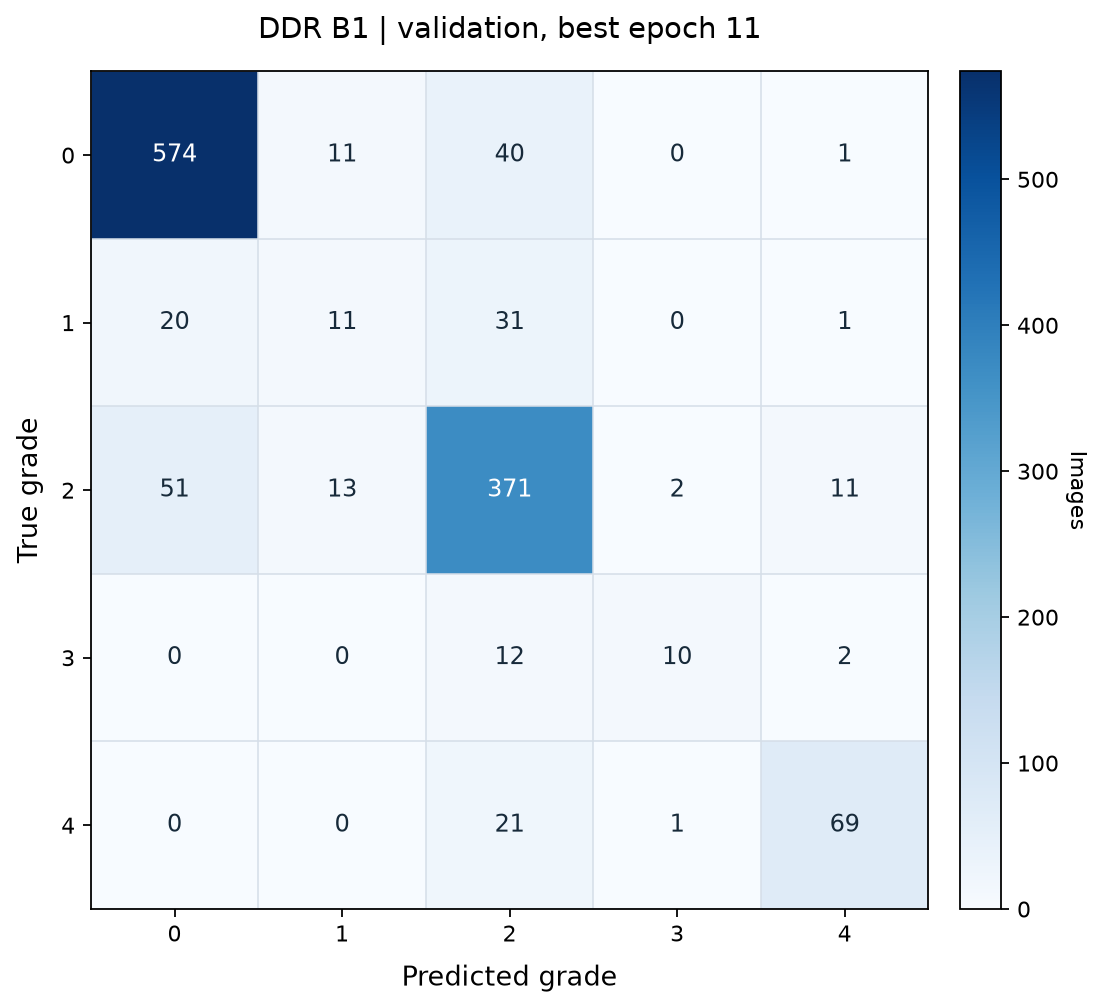

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'novelty/convnext_b0_b4/DDR_B1_confusion_matrix.png')))

The next output displays the original train and validation learning curves. Metric coverage follows the corresponding recorded history.

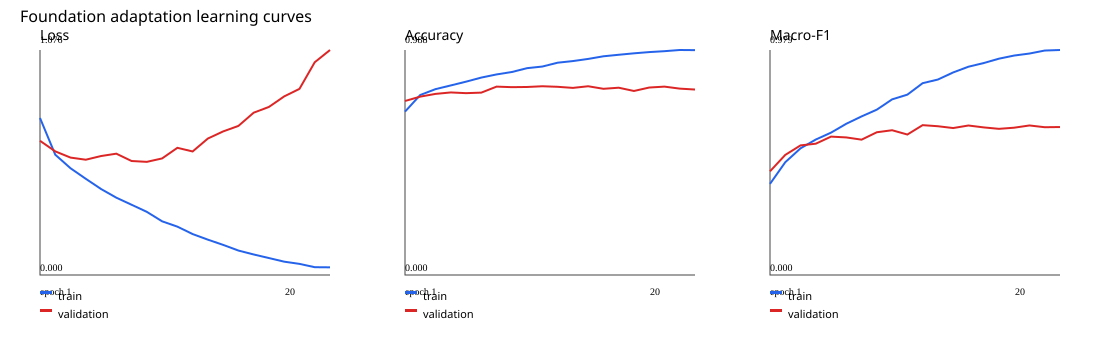

In [ ]:
from IPython.display import SVG
display(SVG(filename=str(ROOT / 'novelty/convnext_b0_b4/DDR_B1_learning_curves.svg')))

## Interpretation and limits

Compared with B0 on this validation split, macro-F1 changed by +0.032329, grade 1 recall by +0.0952, and grade 3 recall by -0.2083.

Screening comparisons share validation data and need independent confirmation. A selected checkpoint is not a final-test result. See the [baseline rationale and audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md#b0b4-mapping).

## Optional execution of the authentic workflow

Set the external `DR_ARTIFACT_ROOT`, `DR_CONVNEXT_SNAPSHOT` and for writing steps `DR_NOTEBOOK_RUN_DIR`. Use the protocol's reviewed cache roots, size budgets and paths when applicable. `DR_MANIFEST_SOURCE_ROOT` supports moved roots for E5–E7. Authorize the local snapshot explicitly via `DR_TRUST_LEGACY_BIN=1` where required. GPU actions also require `DR_GPU_ALLOCATION_CONFIRMED=1`. 

The [shared workflow bridge](../experiment_workflow.py) lists the exact environment keys and dispatches to the original CLI. Choose one step and enable its switch. Outputs must use a fresh external location. Report identity and cache validity remain enforced by the runner.

In [ ]:
from notebooks.experiment_workflow import run_step

ACTION = None
RUN_PREFLIGHT = False
RUN_CACHE = False
RUN_INPUT_VERIFICATION = False
RUN_GPU_SMOKE = False
RUN_BENCHMARK = False
RUN_TRAINING = False
RUN_CHECKPOINT_EXPORT = False
RUN_PRUNING = False
RUN_FINAL_TEST = False
if RUN_CHECKPOINT_EXPORT or RUN_PRUNING or RUN_FINAL_TEST:
    raise ValueError("Export, pruning and final-test inference are outside this workflow.")
run_step(ROOT, METHOD, DATASET, ACTION, CONFIG, {
    "preflight": RUN_PREFLIGHT, "estimate-cache": RUN_PREFLIGHT, "prepare-cache": RUN_CACHE,
    "verify-inputs": RUN_INPUT_VERIFICATION, "smoke": RUN_GPU_SMOKE,
    "benchmark": RUN_BENCHMARK, "train": RUN_TRAINING,
})